In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
from imblearn.over_sampling import RandomOverSampler
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc, precision_recall_fscore_support
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/flight_delay_data/19_20_cleaned_data.csv")
df = df.drop(columns=[
    "TAIL_NUM", "OP_CARRIER_FL_NUM", "DEP_DEL15", "ARR_DEL15",
    "ORIGIN_AIRPORT_SEQ_ID", "DEST_AIRPORT_SEQ_ID"
], errors='ignore')

In [ ]:
# train test split
X = df.drop(columns=['IS_DELAYED'])
y = df['IS_DELAYED']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
# Separate numeric and categorical columns
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

# Scale numeric
scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train[num_cols])
X_test_num = scaler.transform(X_test[num_cols])

# Encode categorical
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_cat = encoder.fit_transform(X_train[cat_cols])
X_test_cat = encoder.transform(X_test[cat_cols])

# Combine all features back
X_train_final = np.hstack([X_train_num, X_train_cat])
X_test_final = np.hstack([X_test_num, X_test_cat])

print(f"Final shape: {X_train_final.shape}")


Final shape: (932184, 748)


In [ ]:
# random forest
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=20,
    max_features='sqrt',
    class_weight='balanced_subsample',
    n_jobs=-1,
    verbose=1,
    random_state=42
)

rf.fit(X_train_final, y_train)
y_pred_rf = rf.predict(X_test_final)
y_proba_rf = rf.predict_proba(X_test_final)[:, 1]


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:   22.9s
[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed:  1.9min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  2.1min finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.2s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    1.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    1.1s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.2s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    1.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    1.1s finished


In [ ]:
brf = BalancedRandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    sampling_strategy='auto',
    n_jobs=-1,
    random_state=42
)

brf.fit(X_train_final, y_train)
y_pred_brf = brf.predict(X_test_final)
y_proba_brf = brf.predict_proba(X_test_final)[:, 1]


Random Forest
Accuracy:  0.6506
ROC-AUC:   0.7468

Classification Report:
              precision    recall  f1-score   support

           0      0.898     0.638     0.746    187544
           1      0.320     0.702     0.440     45503

    accuracy                          0.651    233047
   macro avg      0.609     0.670     0.593    233047
weighted avg      0.785     0.651     0.686    233047



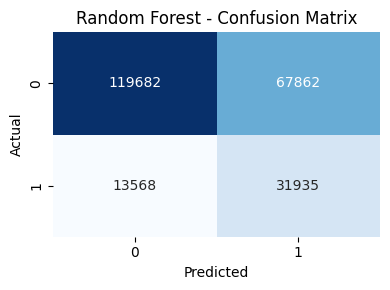


Balanced Random Forest
Accuracy:  0.6601
ROC-AUC:   0.7585

Classification Report:
              precision    recall  f1-score   support

           0      0.902     0.648     0.754    187544
           1      0.329     0.712     0.450     45503

    accuracy                          0.660    233047
   macro avg      0.616     0.680     0.602    233047
weighted avg      0.790     0.660     0.695    233047



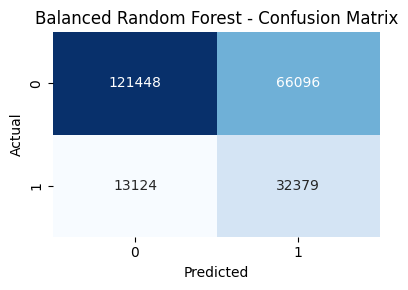

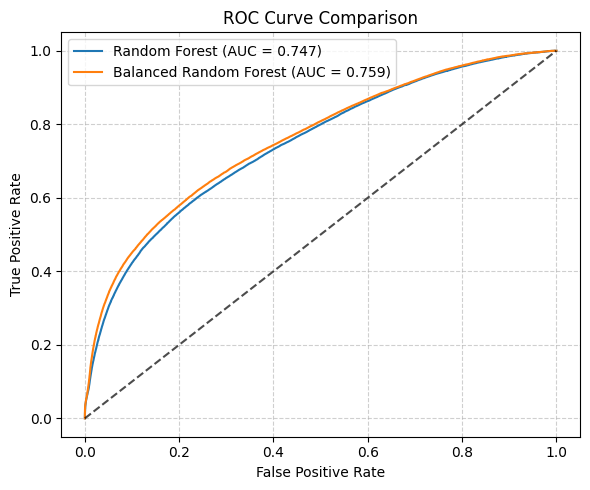

In [ ]:
models = {
    "Random Forest": (y_pred_rf, y_proba_rf),
    "Balanced Random Forest": (y_pred_brf, y_proba_brf),
}

# Text + Confusion Matrices
for name, (y_pred, y_proba) in models.items():
    print(f"\n{'='*25}\n{name}\n{'='*25}")
    print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, digits=3))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

# ROC Curve Comparison
plt.figure(figsize=(6, 5))
for name, (_, y_proba) in models.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.7)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()